In [1]:
# import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [2]:
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

# convert the date column into datetime format
df["date"] = pd.to_datetime(df["date"])
display(df.head())
print("dataset shape:", df.shape)
print("columns:", df.columns.tolist())

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


dataset shape: (177990, 14)
columns: ['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']


In [3]:
# calculate revenue for each record
df["sales_revenue"] = df["units_sold"] * df["unit_price"]

# remove records with missing dates or invalid sales values
df = df.dropna(subset=["date", "units_sold", "unit_price"])
df = df[df["units_sold"] >= 0]
df = df[df["unit_price"] >= 0]

# group all regions, medicines and categories by date
daily_sales = df.groupby("date")["sales_revenue"].sum()

# sort dates from oldest to newest
daily_sales = daily_sales.sort_index()

# include every calendar date in the series
daily_sales = daily_sales.asfreq("D")

# fill any missing daily totals with zero
# this assumes a missing date means no recorded sales
daily_sales = daily_sales.fillna(0)

# display the prepared time series
print("first date:", daily_sales.index.min())
print("last date:", daily_sales.index.max())
print("number of daily observations:", len(daily_sales))

print(daily_sales.head())

first date: 2020-01-01 00:00:00
last date: 2025-12-31 00:00:00
number of daily observations: 2192
date
2020-01-01    3069325.55
2020-01-02    3792212.65
2020-01-03    2579306.04
2020-01-04    2674030.68
2020-01-05    3004000.06
Freq: D, Name: sales_revenue, dtype: float64


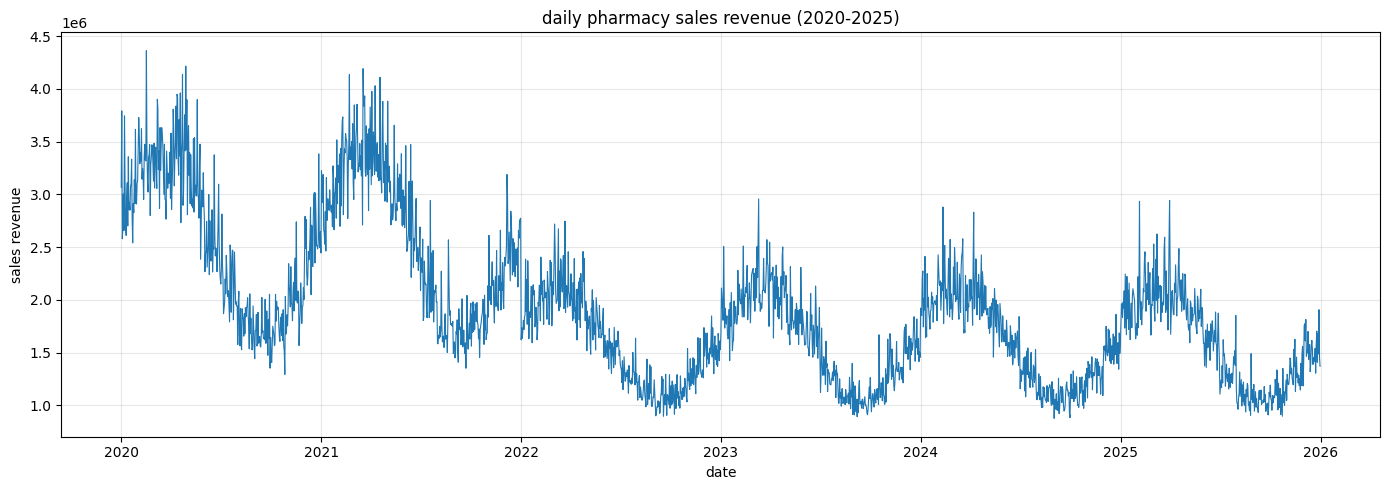

In [4]:
# plot daily sales revenue

plt.figure(figsize=(14, 5))
plt.plot(daily_sales, linewidth=0.8)
plt.title("daily pharmacy sales revenue (2020-2025)")
plt.xlabel("date")
plt.ylabel("sales revenue")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

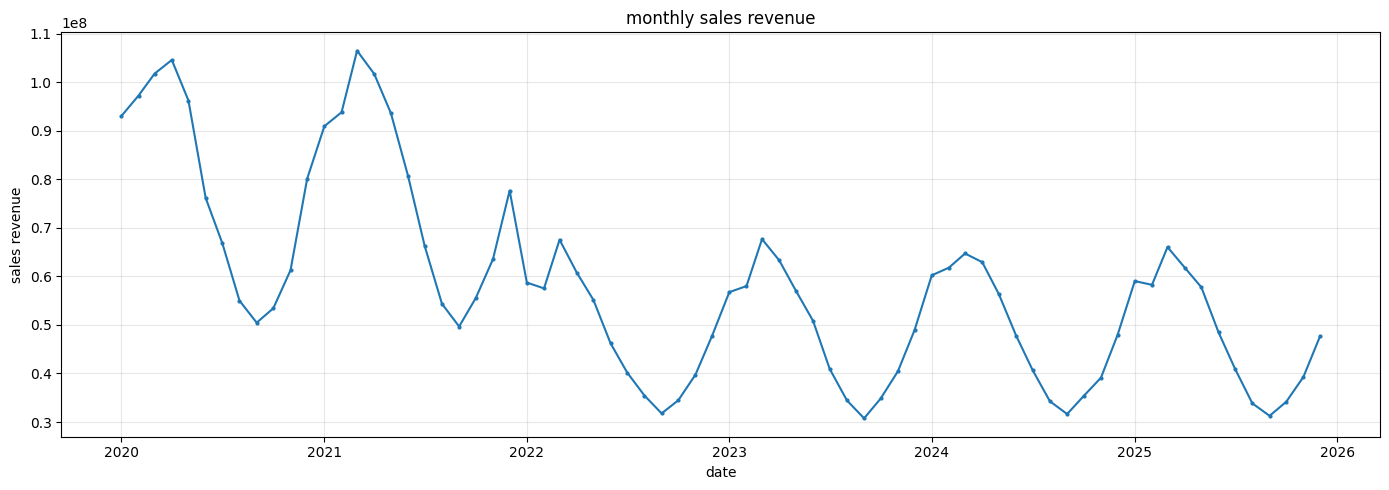

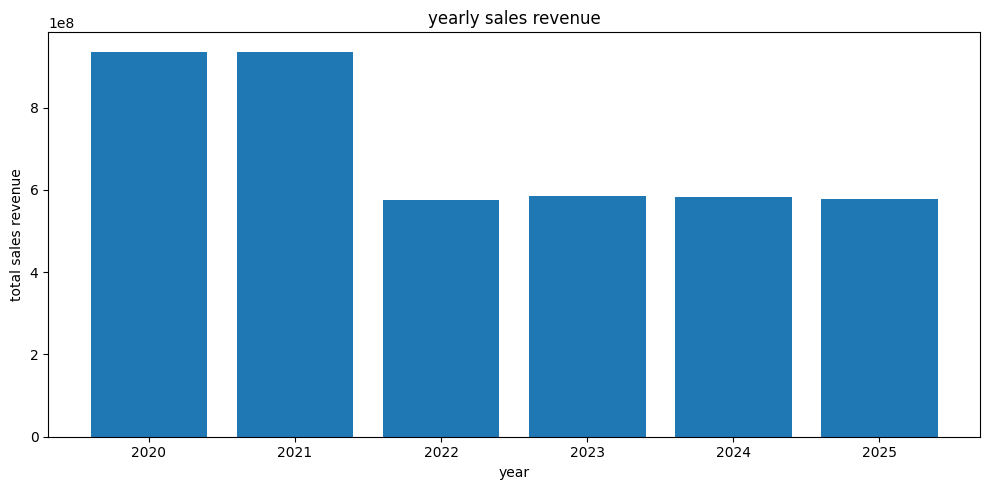

In [5]:
# calculate monthly sales totals
monthly_sales = daily_sales.resample("MS").sum()

# calculate yearly sales totals
yearly_sales = daily_sales.resample("YS").sum()

# plot monthly sales
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales, marker="o", markersize=2)
plt.title("monthly sales revenue")
plt.xlabel("date")
plt.ylabel("sales revenue")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# plot yearly sales
plt.figure(figsize=(10, 5))
plt.bar(yearly_sales.index.year.astype(str), yearly_sales.values)
plt.title("yearly sales revenue")
plt.xlabel("year")
plt.ylabel("total sales revenue")
plt.tight_layout()
plt.show()

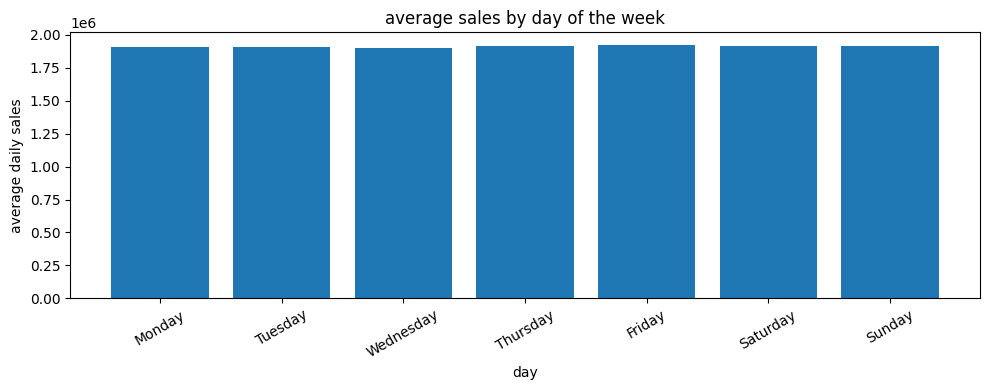

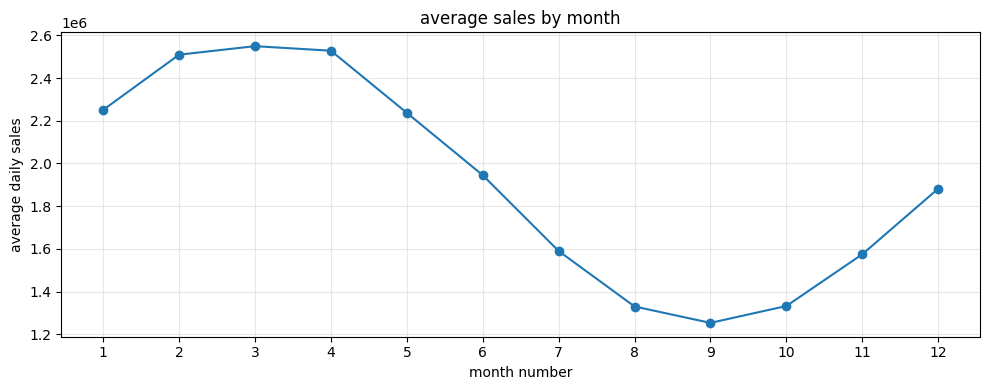

In [6]:
# add calendar information to the daily data
sales_data = daily_sales.to_frame(name="sales_revenue")
sales_data["day_name"] = sales_data.index.day_name()
sales_data["month_name"] = sales_data.index.month_name()

# calculate average sales for each day of the week
weekly_pattern = sales_data.groupby("day_name")["sales_revenue"].mean()

# arrange the days in calendar order
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekly_pattern = weekly_pattern.reindex(day_order)

# calculate average sales for each month
monthly_pattern = sales_data.groupby(
    sales_data.index.month
)["sales_revenue"].mean()

# plot weekly seasonality
plt.figure(figsize=(10, 4))
plt.bar(weekly_pattern.index, weekly_pattern.values)
plt.title("average sales by day of the week")
plt.xlabel("day")
plt.ylabel("average daily sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# plot monthly seasonality
plt.figure(figsize=(10, 4))
plt.plot(monthly_pattern.index, monthly_pattern.values, marker="o")
plt.title("average sales by month")
plt.xlabel("month number")
plt.ylabel("average daily sales")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

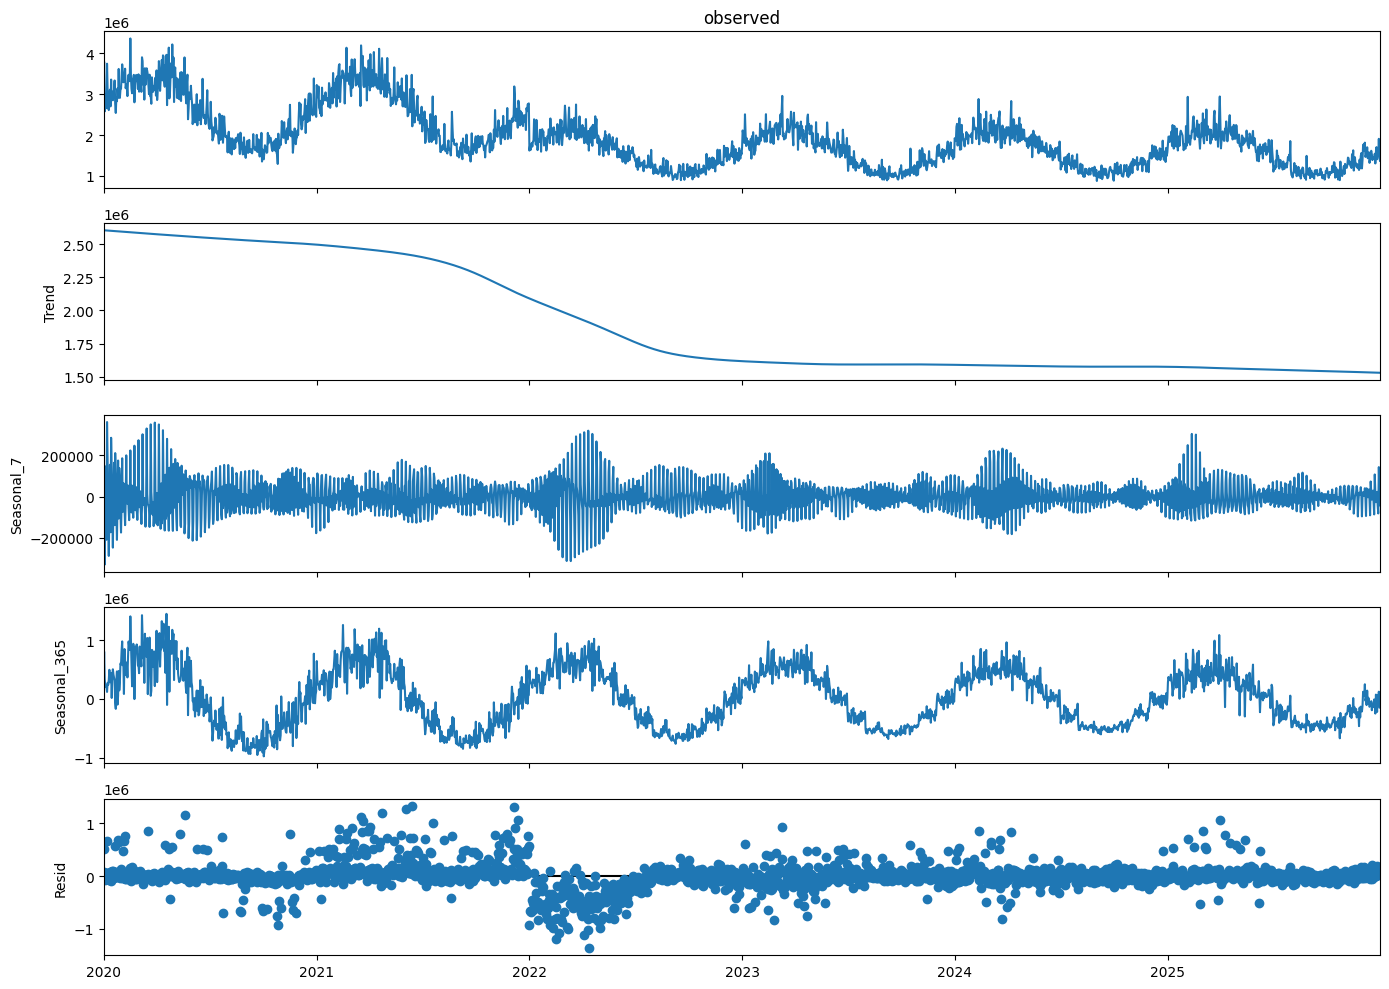

In [7]:
# perform decomposition with weekly and yearly seasonality
mstl_model = MSTL(
    daily_sales,
    periods=[7, 365],
    stl_kwargs={"robust": True}
)

mstl_result = mstl_model.fit()

# display the decomposition graphs
mstl_result.plot()
plt.gcf().set_size_inches(14, 10)
plt.tight_layout()
plt.show()

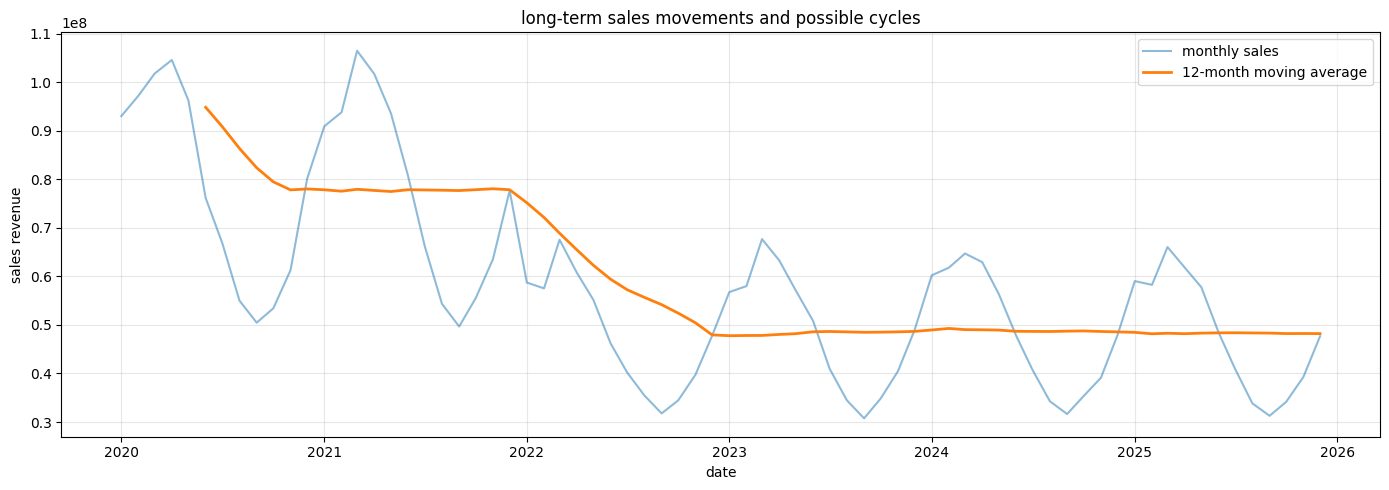

In [8]:
# calculate monthly sales totals
monthly_sales = daily_sales.resample("MS").sum()

# calculate a 12-month moving average
monthly_trend = monthly_sales.rolling(
    window=12,
    min_periods=6
).mean()

# plot monthly sales and the smoothed trend
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales, label="monthly sales", alpha=0.5)
plt.plot(monthly_trend, label="12-month moving average", linewidth=2)
plt.title("long-term sales movements and possible cycles")
plt.xlabel("date")
plt.ylabel("sales revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# use the final 30 days as test data
test_days = 30
train = daily_sales.iloc[:-test_days]
test = daily_sales.iloc[-test_days:]

print("training observations:", len(train))
print("testing observations:", len(test))
print("test begins:", test.index.min())
print("test ends:", test.index.max())

training observations: 2162
testing observations: 30
test begins: 2025-12-02 00:00:00
test ends: 2025-12-31 00:00:00


In [10]:
# create the seasonal arima model
model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# train the model
model_fit = model.fit(disp=False)

# predict sales for the test period
predictions = model_fit.forecast(steps=len(test))
print("forecast completed")
print(predictions.head())

forecast completed
2025-12-02    1.353366e+06
2025-12-03    1.347702e+06
2025-12-04    1.407563e+06
2025-12-05    1.412230e+06
2025-12-06    1.458092e+06
Freq: D, Name: predicted_mean, dtype: float64


In [11]:
# calculate prediction errors
mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))

# avoid division by zero when calculating mape
actual_values = test.values
predicted_values = predictions.values
non_zero = actual_values != 0
if non_zero.sum() > 0:
    mape = np.mean(
        np.abs(
            (actual_values[non_zero] - predicted_values[non_zero])
            / actual_values[non_zero]
        )
    ) * 100
else:
    mape = np.nan

print("mean absolute error:", round(mae, 2))
print("root mean squared error:", round(rmse, 2))
print("mean absolute percentage error:", round(mape, 2), "%")

mean absolute error: 162188.58
root mean squared error: 202393.53
mean absolute percentage error: 10.05 %


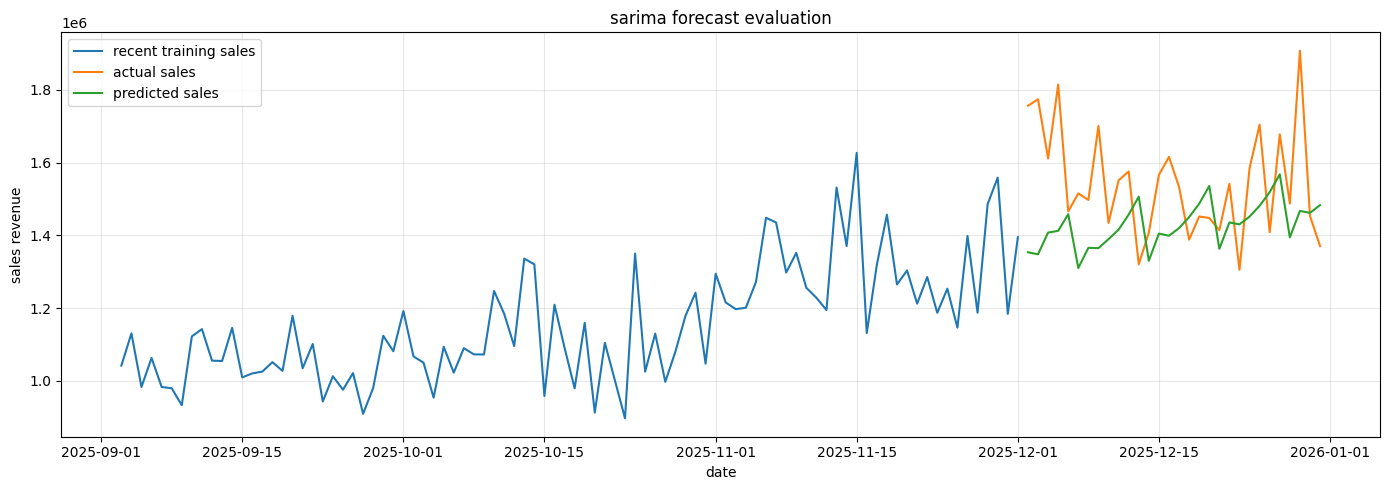

In [12]:
# compare actual sales with forecast sales

plt.figure(figsize=(14, 5))
plt.plot(train.tail(90), label="recent training sales")
plt.plot(test, label="actual sales")
plt.plot(predictions, label="predicted sales")
plt.title("sarima forecast evaluation")
plt.xlabel("date")
plt.ylabel("sales revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# train the final model using all historical sales
final_model = SARIMAX(
    daily_sales,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_fit = final_model.fit(disp=False)

# forecast the next 30 days
future_forecast = final_fit.get_forecast(steps=30)
forecast_values = future_forecast.predicted_mean
forecast_interval = future_forecast.conf_int()

# display the forecast

forecast_table = pd.DataFrame({
    "forecast_sales": forecast_values,
    "lower_bound": forecast_interval.iloc[:, 0],
    "upper_bound": forecast_interval.iloc[:, 1]
})

print(forecast_table.round(2))

            forecast_sales  lower_bound  upper_bound
2026-01-01      1552470.23    900441.51   2204498.94
2026-01-02      1560723.66    886348.73   2235098.59
2026-01-03      1530490.12    829666.23   2231314.01
2026-01-04      1455762.23    729639.92   2181884.54
2026-01-05      1597485.48    846909.94   2348061.01
2026-01-06      1542812.29    768555.70   2317068.87
2026-01-07      1557164.38    759929.85   2354398.90
2026-01-08      1592089.41    744923.10   2439255.72
2026-01-09      1568477.72    694329.26   2442626.19
2026-01-10      1574731.19    673747.50   2475714.88
2026-01-11      1485825.17    558807.72   2412842.62
2026-01-12      1661704.36    709363.63   2614045.10
2026-01-13      1557990.00    580982.15   2534997.84
2026-01-14      1560440.73    559373.40   2561508.05
2026-01-15      1613437.94    541668.51   2685207.37
2026-01-16      1593735.45    490493.79   2696977.11
2026-01-17      1595512.71    460581.72   2730443.70
2026-01-18      1508346.05    342628.21   2674

In [14]:
# identify the highest and lowest average sales weekdays

best_day = weekly_pattern.idxmax()
low_day = weekly_pattern.idxmin()

# identify the month with the highest average daily sales

best_month = monthly_pattern.idxmax()

# calculate average historical and forecast daily sales

historical_average = daily_sales.mean()
forecast_average = forecast_values.mean()

# calculate the percentage change in forecast average

if historical_average != 0:
    forecast_change = (
        (forecast_average - historical_average)
        / historical_average
    ) * 100
else:
    forecast_change = np.nan

# display the insights

print("actionable sales insights\n")

print("highest average sales weekday:", best_day)
print("lowest average sales weekday:", low_day)
print("highest average sales month:", best_month)

print("forecast average daily sales:", round(forecast_average, 2))
# calculate total forecast revenue for the next 30 days

print("expected revenue for next 30 days:",
      round(forecast_values.sum(), 2))

actionable sales insights

highest average sales weekday: Friday
lowest average sales weekday: Wednesday
highest average sales month: 3
forecast average daily sales: 1586068.82
expected revenue for next 30 days: 47582064.67
